# 14 · Optimization: gradient descent, momentum, Adam, schedules and clipping

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
np.seterr(over="ignore", invalid="ignore")

def rosenbrock(p):
    x, y = p[..., 0], p[..., 1]
    return (1 - x) ** 2 + 100 * (y - x**2) ** 2

def run(opt_name, lr, steps=2000, start=(-1.5, 2.0), **kw):
    p = torch.tensor(start, requires_grad=True)
    opt = {"sgd": torch.optim.SGD, "adam": torch.optim.Adam}[opt_name]([p], lr=lr, **kw)
    path = [p.detach().clone()]
    for _ in range(steps):
        loss = rosenbrock(p)
        opt.zero_grad(); loss.backward(); opt.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()

def contour(ax):
    X, Y = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-1, 3, 300))
    ax.contour(X, Y, rosenbrock(np.stack([X, Y], -1)), levels=np.logspace(-1, 3.5, 20), cmap="gray", linewidths=0.5)
    ax.plot(1, 1, "r*", ms=15)

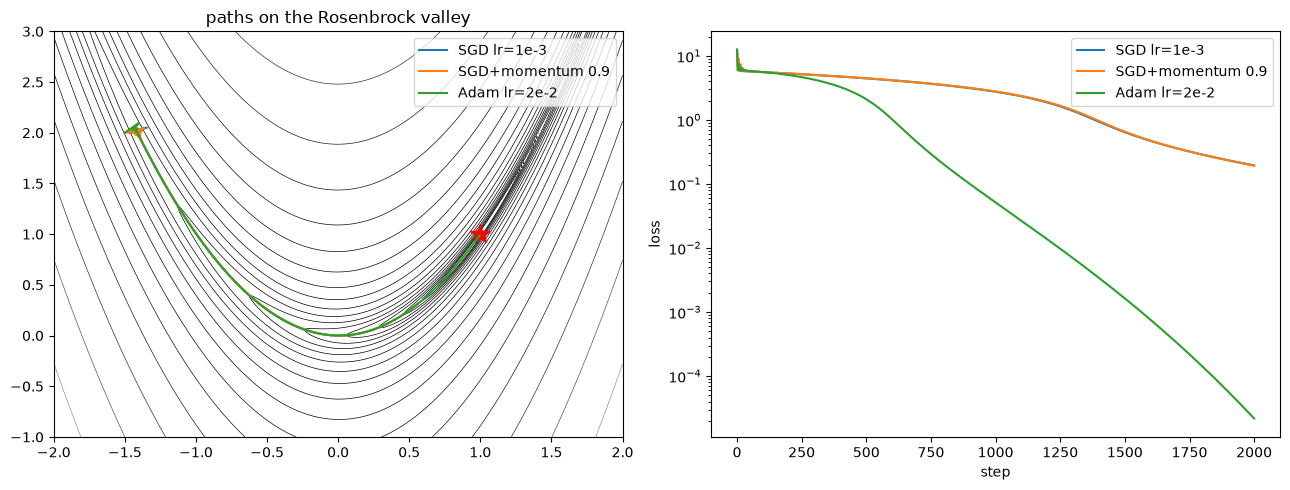

In [2]:
configs = {"SGD lr=1e-3": ("sgd", 1e-3, {}),
           "SGD+momentum 0.9": ("sgd", 1e-4, {"momentum": 0.9}),
           "Adam lr=2e-2": ("adam", 2e-2, {})}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
contour(ax[0])
for name, (o, lr, kw) in configs.items():
    path = run(o, lr, **kw)
    ax[0].plot(*path.T, lw=1.5, label=name)
    ax[1].semilogy(rosenbrock(path), label=name)
ax[0].legend(); ax[0].set_title("paths on the Rosenbrock valley"); ax[1].set_xlabel("step"); ax[1].set_ylabel("loss"); ax[1].legend()
plt.tight_layout(); plt.show()

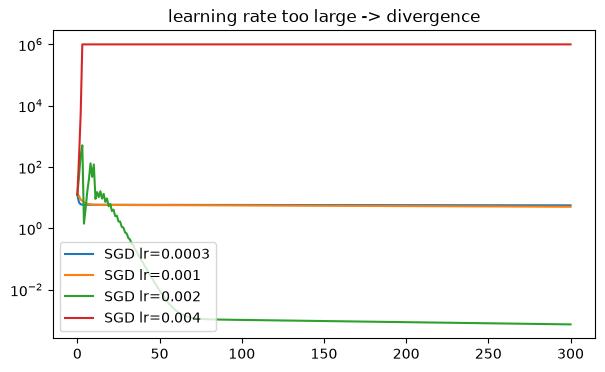

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(7, 4))
for lr in [3e-4, 1e-3, 2e-3, 4e-3]:
    path = run("sgd", lr, steps=300)
    loss = np.nan_to_num(rosenbrock(path), nan=1e6, posinf=1e6)
    ax.semilogy(np.clip(loss, 1e-4, 1e6), label=f"SGD lr={lr}")
ax.set_title("learning rate too large -> divergence"); ax.legend(); plt.show()

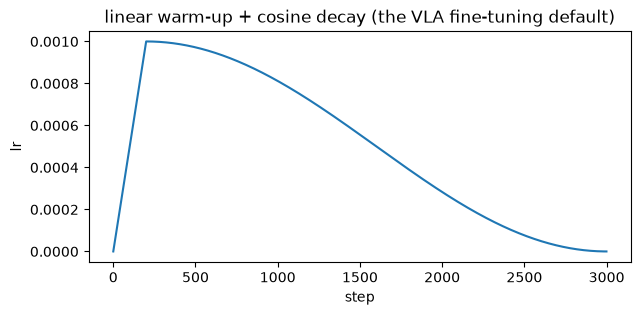

In [4]:
steps = np.arange(3000)
warm = 200
cosine = np.where(steps < warm, steps / warm, 0.5 * (1 + np.cos(np.pi * (steps - warm) / (3000 - warm))))
plt.figure(figsize=(7, 3)); plt.plot(steps, 1e-3 * cosine); plt.title("linear warm-up + cosine decay (the VLA fine-tuning default)"); plt.xlabel("step"); plt.ylabel("lr"); plt.show()

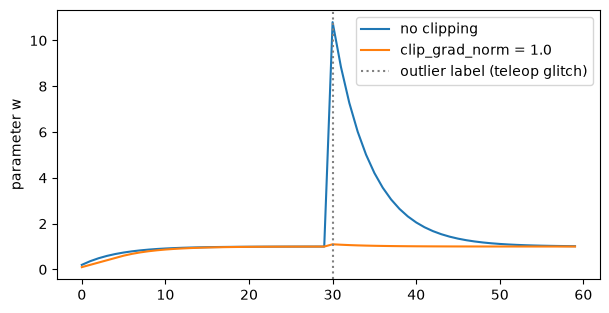

In [5]:
torch.manual_seed(0)
w = torch.zeros(1, requires_grad=True)
grads = []
for clip in [None, 1.0]:
    w.data.zero_(); trace = []
    opt = torch.optim.SGD([w], lr=0.1)
    for t in range(60):
        target = torch.tensor([50.0]) if t == 30 else torch.tensor([1.0])
        loss = ((w - target) ** 2).sum()
        opt.zero_grad(); loss.backward()
        if clip:
            torch.nn.utils.clip_grad_norm_([w], clip)
        opt.step(); trace.append(w.item())
    grads.append(trace)
plt.figure(figsize=(7, 3.5)); plt.plot(grads[0], label="no clipping"); plt.plot(grads[1], label="clip_grad_norm = 1.0")
plt.axvline(30, c="gray", ls=":", label="outlier label (teleop glitch)"); plt.legend(); plt.ylabel("parameter w"); plt.show()